# Customer Churn Prediction
**Week 2 Assignment: Messy Data, Cleaning and Model Training** | Data Science Mentorship

This notebook takes the Telco Customer Churn data from raw CSV to a cleaned, documented and fairly evaluated machine-learning workflow. It compares a baseline, Logistic Regression and Random Forest using 5-fold stratified cross-validation.

## 1. Business Problem and Objective

**Business context.** A telecom company selling phone and internet services loses revenue every time a customer cancels. Winning a new customer usually costs more than keeping an existing one, so the company wants to spot customers who are likely to leave early enough to act, for example with a retention call, a discount, or an offer to move to a longer contract.

**Objective.** Predict whether a customer will churn (leave the company) from their account, service and billing information.

**Target variable.** `Churn`. "Yes" means the customer left and "No" means they stayed. It is encoded as 1 (churn) and 0 (no churn) later in the notebook.

**Potential business value.** A model that ranks customers by churn risk lets the retention team spend a limited budget on the customers most likely to leave instead of contacting everyone. The features that matter most can also point to which customer groups (contract type, billing method, services) are most at risk, which helps with pricing and product decisions.

## 2. Dataset Source and Initial Inspection

**Source.** Telco Customer Churn, a sample dataset originally published by IBM and widely shared on Kaggle. Each row is one customer (7,043 rows, 21 columns).

**Data access.** The CSV is expected at `data/Telco-Customer-Churn.csv` (the notebook also checks `../data/` and the current folder). If the file is not found and the notebook is running in Google Colab, the next cell opens an upload prompt for the CSV. The original file is never modified, all cleaning happens in memory.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import make_scorer, precision_score, confusion_matrix, ConfusionMatrixDisplay
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [2]:
#paths = ['data/Telco-Customer-Churn.csv', '../data/Telco-Customer-Churn.csv', 'Telco-Customer-Churn.csv']
#data_path = next((p for p in paths if os.path.exists(p)), None)

#if data_path is None:
#    from google.colab import files
#    uploaded = files.upload()
#    data_path = list(uploaded.keys())[0]

#df = pd.read_csv(data_path)
#raw_df = df.copy()
#print(df.shape)

In [3]:
df = pd.read_csv(r"D:\Work\Projects\Python\CSV Files\Telco-Customer-Churn.csv")
raw_df = df.copy()
print(df.shape)

(7043, 21)


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
print(df['Churn'].value_counts())
print()
print((df['Churn'].value_counts(normalize=True) * 100).round(2))

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


The dataset has 7,043 customers and 21 columns. Only 3 columns are numeric (`tenure`, `MonthlyCharges` and `SeniorCitizen`, which is really a 0/1 flag), the rest are text. About 26.5% of customers churned, so the classes are imbalanced. That already matters for the choice of metric and for how the folds are built.

## 3. Data Quality Report

Before fixing anything I scan the whole table for missing values, blank strings, duplicates and the number of distinct values per column.

In [8]:
quality_report = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isnull().sum(),
    'blank_strings': df.apply(lambda s: s.astype(str).str.strip().eq('').sum()),
    'unique_values': df.nunique()
})
quality_report

,dtype,missing,blank_strings,unique_values
customerID,str,0,0,7043
gender,str,0,0,2
SeniorCitizen,int64,0,0,2
Partner,str,0,0,2
Dependents,str,0,0,2
tenure,int64,0,0,73
PhoneService,str,0,0,2
MultipleLines,str,0,0,3
InternetService,str,0,0,3
OnlineSecurity,str,0,0,3


In [9]:
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate customerIDs:', df['customerID'].duplicated().sum())

Duplicate rows: 0
Duplicate customerIDs: 0


Nothing shows up as missing, but `TotalCharges` has blank strings and is stored as text, and several categorical columns carry labels that repeat information from other columns. The next five sections document each problem with the format **Problem → Evidence → Fix → Justification**.

## 4. Data Quality Problems, Cleaning Code and Reasoning

### Problem 1: `TotalCharges` is stored as text

**Problem.** `TotalCharges` is a money amount, but pandas loaded it as a string column.

**Evidence.** The dtype and the entries that cannot be read as numbers are shown below.

In [10]:
print('dtype:', df['TotalCharges'].dtype)
not_numeric = pd.to_numeric(df['TotalCharges'], errors='coerce').isnull()
print('entries that are not valid numbers:', not_numeric.sum())

dtype: str
entries that are not valid numbers: 11


**Fix.** Strip whitespace and convert the column with `pd.to_numeric(..., errors='coerce')`.

**Justification.** Scalers and models need numeric input. I used `errors='coerce'` instead of dropping the column or the rows, because it keeps all the data and turns the unreadable entries into proper missing values that I can investigate in Problem 2. With the default `errors='raise'` the conversion would simply crash without telling me how many entries were bad.

In [11]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')
print('dtype after fix:', df['TotalCharges'].dtype)
print('missing after fix:', df['TotalCharges'].isnull().sum())

dtype after fix: float64
missing after fix: 11


### Problem 2: Missing `TotalCharges` values that belong to brand-new customers

**Problem.** After the conversion, `TotalCharges` has missing values that need a decision.

**Evidence.** Looking at which rows are missing shows a clear pattern.

In [12]:
missing_total = df['TotalCharges'].isnull()
print('missing TotalCharges:', missing_total.sum())
print()
print('tenure of those rows:')
print(df.loc[missing_total, 'tenure'].value_counts())
print()
print('Churn of those rows:')
print(df.loc[missing_total, 'Churn'].value_counts())
print()
print('customers with tenure == 0 in the whole data:', (df['tenure'] == 0).sum())
print('mean TotalCharges of everyone else:', round(df['TotalCharges'].mean(), 2))

missing TotalCharges: 11

tenure of those rows:
tenure
0    11
Name: count, dtype: int64

Churn of those rows:
Churn
No    11
Name: count, dtype: int64

customers with tenure == 0 in the whole data: 11
mean TotalCharges of everyone else: 2283.3


**Fix.** Set `TotalCharges` to 0 for these customers.

**Justification.** All of the missing rows have `tenure == 0`, and every customer with `tenure == 0` is in the missing group. These customers just signed up and have not been billed yet, so a total of 0 is the true value, not a guess. Filling with the mean (which is what a quick fix would do) would claim that a customer in their first month has already paid more than 2,000, which is wrong and would distort the feature. Dropping the rows would lose 11 valid customers for no reason. Because the rule ("no tenure means no charges yet") is fixed and does not learn anything from the data, it is safe to apply before cross-validation without causing leakage.

In [13]:
fix_mask = df['TotalCharges'].isnull() & (df['tenure'] == 0)
df.loc[fix_mask, 'TotalCharges'] = 0
print('rows fixed:', fix_mask.sum())
print('missing TotalCharges now:', df['TotalCharges'].isnull().sum())

rows fixed: 11
missing TotalCharges now: 0


### Problem 3: `MultipleLines` repeats information from `PhoneService`

**Problem.** `MultipleLines` has three values, "Yes", "No" and "No phone service". The third one is not really a separate answer, it just restates that the customer has no phone service.

**Evidence.**

In [14]:
print(df['MultipleLines'].value_counts())
print()

MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64



**Fix.** Replace "No phone service" with "No" in `MultipleLines`.

**Justification.** Every "No phone service" row has `PhoneService == 'No'` and the other way around, so the label adds no new information. `PhoneService` stays in the data, so nothing is lost. Keeping the third label would create an extra dummy column that is an exact copy of `PhoneService = No`, which is redundant and can make linear models unstable.

In [15]:
df['MultipleLines'] = df['MultipleLines'].replace('No phone service', 'No')
print(df['MultipleLines'].value_counts())

MultipleLines
No     4072
Yes    2971
Name: count, dtype: int64


### Problem 4: "No internet service" repeated across six columns

**Problem.** Six add-on columns (`OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`) use a third label, "No internet service", that duplicates what `InternetService` already says.

**Evidence.** The number of "No internet service" entries in each column is compared with the number of customers who have `InternetService == 'No'`.

In [16]:
internet_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
print('customers with InternetService == No:', (df['InternetService'] == 'No').sum())
print()
for col in internet_cols:
    n_label = (df[col] == 'No internet service').sum()
    n_match = ((df[col] == 'No internet service') & (df['InternetService'] == 'No')).sum()
    print(f'{col:18} label count = {n_label}, of which InternetService == No: {n_match}')

customers with InternetService == No: 1526

OnlineSecurity     label count = 1526, of which InternetService == No: 1526
OnlineBackup       label count = 1526, of which InternetService == No: 1526
DeviceProtection   label count = 1526, of which InternetService == No: 1526
TechSupport        label count = 1526, of which InternetService == No: 1526
StreamingTV        label count = 1526, of which InternetService == No: 1526
StreamingMovies    label count = 1526, of which InternetService == No: 1526


**Fix.** Replace "No internet service" with "No" in those six columns.

**Justification.** The label appears exactly for the customers without internet, so it is a copy of `InternetService = No`, repeated six times. After the fix each add-on column is a clean yes/no question. The distinction between "has internet but no security" and "has no internet at all" is not lost, because `InternetService` stays as a feature. Keeping the label would add six redundant dummy columns that are perfectly collinear with each other.

In [17]:
df[internet_cols] = df[internet_cols].replace('No internet service', 'No')
for col in internet_cols:
    print(col, df[col].unique().tolist())

OnlineSecurity ['No', 'Yes']
OnlineBackup ['Yes', 'No']
DeviceProtection ['No', 'Yes']
TechSupport ['No', 'Yes']
StreamingTV ['No', 'Yes']
StreamingMovies ['No', 'Yes']


### Problem 5: `SeniorCitizen` uses a different coding from the other yes/no columns

**Problem.** `SeniorCitizen` is stored as 0/1 integers while every other yes/no column (`Partner`, `Dependents`, `PhoneService`, `PaperlessBilling`, ...) uses the text values "Yes" and "No".

**Evidence.**

In [18]:
print('SeniorCitizen:', df['SeniorCitizen'].unique().tolist())
for col in ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']:
    print(col + ':', df[col].unique().tolist())

SeniorCitizen: [0, 1]
Partner: ['Yes', 'No']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
PaperlessBilling: ['Yes', 'No']


**Fix.** Map `SeniorCitizen` from 1/0 to "Yes"/"No".

**Justification.** With one coding for all binary columns, a single encoder in the pipeline can treat them all the same way. With the mixed coding it would be easy to push `SeniorCitizen` through the numeric scaler by mistake, which makes no sense for a flag. I chose to convert it to text instead of converting the other columns to 0/1 because the text version is easier to read in the cleaning code and the encoder produces the 0/1 columns anyway.

In [19]:
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
print(df['SeniorCitizen'].value_counts())

SeniorCitizen
No     5901
Yes    1142
Name: count, dtype: int64


### Cleaning verification

A before-and-after comparison confirms that the fixes did what they were supposed to do and that no rows were lost.

In [20]:
print('rows before / after:', raw_df.shape[0], '/', df.shape[0])
print('columns before / after:', raw_df.shape[1], '/', df.shape[1])
print('missing values after cleaning:', df.isnull().sum().sum())
print()
changed = pd.DataFrame({'before': raw_df.dtypes.astype(str), 'after': df.dtypes.astype(str)})
changed[changed['before'] != changed['after']]

rows before / after: 7043 / 7043
columns before / after: 21 / 21
missing values after cleaning: 0



,before,after
SeniorCitizen,int64,str
TotalCharges,str,float64


In [21]:
for col in ['MultipleLines'] + internet_cols + ['SeniorCitizen']:
    print(col, df[col].unique().tolist())

MultipleLines ['No', 'Yes']
OnlineSecurity ['No', 'Yes']
OnlineBackup ['Yes', 'No']
DeviceProtection ['No', 'Yes']
TechSupport ['No', 'Yes']
StreamingTV ['No', 'Yes']
StreamingMovies ['No', 'Yes']
SeniorCitizen ['No', 'Yes']


### Summary of data quality problems

| # | Problem | Evidence | Fix |
|---|---------|----------|-----|
| 1 | `TotalCharges` stored as text | object dtype, 11 entries that are blank strings | Strip and convert with `pd.to_numeric` |
| 2 | Missing `TotalCharges` after conversion | 11 rows, all with `tenure == 0` | Set to 0 (not yet billed) |
| 3 | "No phone service" repeats `PhoneService` | 682 rows, all with `PhoneService == No` | Replace with "No" |
| 4 | "No internet service" repeated in 6 columns | 1,526 rows per column, all with `InternetService == No` | Replace with "No" |
| 5 | `SeniorCitizen` coded 0/1, other flags are Yes/No | mixed coding shown above | Map to "Yes" / "No" |

## 5. Features and Target

**Target (`y`).** `Churn`, encoded as 1 for "Yes" and 0 for "No".

**Features (`X`).** All remaining columns after dropping the two below. That leaves 19 features: demographics (`gender`, `SeniorCitizen`, `Partner`, `Dependents`), account information (`tenure`, `Contract`, `PaperlessBilling`, `PaymentMethod`), services (`PhoneService`, `MultipleLines`, `InternetService` and the six add-ons) and billing (`MonthlyCharges`, `TotalCharges`).

**Columns removed.**
- `Churn`: this is the target, so it cannot be an input.
- `customerID`: a unique identifier with no predictive meaning. Left in, a model (especially a random forest) could use it to memorise individual customers.

In [22]:
y = df['Churn'].map({'No': 0, 'Yes': 1})
X = df.drop(columns=['Churn', 'customerID'])

print('X shape:', X.shape)
print('y shape:', y.shape)

X shape: (7043, 19)
y shape: (7043,)


### Data leakage check

- **Target and ID.** Both are removed from `X`, as shown above.
- **Preprocessing.** Scaling, encoding and oversampling all learn something from the data. They are fitted inside a pipeline, so in every cross-validation round they only see the training folds. Nothing is fitted on the full dataset before the split.
- **`TotalCharges` and `tenure`.** `TotalCharges` is almost exactly `tenure × MonthlyCharges`, so it is mostly redundant. This is not target leakage, because it is built from billing history and not from the churn label, but I am keeping it in mind when reading the results.
- **A subtler risk.** In this snapshot, `tenure` for a churned customer is the time until they left, while for a current customer it is the time so far. In real use, `tenure` would be measured at the moment of prediction. This is a limitation to keep in mind, it does not create an obvious leak that I can remove.

## 6. Evaluation Metric Justification

**Primary metrics: ROC-AUC and recall on the churn class.** Precision and accuracy are reported as supporting metrics.

- **ROC-AUC** measures how well a model separates churners from non-churners across all thresholds. It does not depend on one cut-off and is not fooled by class imbalance, so it is a fair way to compare models. It also matches how the model would be used, which is to rank customers by risk.
- **Recall** answers "of the customers who really left, how many did the model catch?". That is the main goal here, because every missed churner is a lost customer.
- **Precision** answers "of the customers flagged as churners, how many really would have left?". It is needed next to recall, because a model that flags everybody gets perfect recall and is useless.
- **Accuracy** is reported but not trusted on its own. About 73.5% of customers do not churn, so a model that always predicts "No churn" is already about 73.5% accurate while finding zero churners.

**Cost of the two errors.**
- *False negative* (a churner is predicted to stay): the company does nothing and loses the customer and all of their future revenue. This is usually the more expensive mistake.
- *False positive* (a loyal customer is predicted to churn): the company spends a retention offer or discount on someone who would have stayed anyway. This costs money and can train customers to expect discounts, but it is normally cheaper than losing the customer.

Because of this, recall is favoured over precision, but not at any price. The dataset does not contain real cost figures, so this trade-off is a reasoned assumption, not a calculated result. All models use the default 0.5 decision threshold.

## 7. Preprocessing Pipeline

All data-dependent preprocessing lives inside a pipeline, so it is re-fitted on the training part of every fold:

1. **`StandardScaler`** on the three numeric columns (`tenure`, `MonthlyCharges`, `TotalCharges`).
2. **`OneHotEncoder`** on every categorical column. Columns with two values become one 0/1 column (`drop='if_binary'`), columns with more values keep all their levels. `handle_unknown='ignore'` stops the pipeline from failing if a level is missing from a training fold.
3. **`SMOTE`** to balance the classes. It is placed after the encoder and is only applied while fitting, so the validation fold always keeps its real class proportions.

In [23]:
numeric_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical_cols = [col for col in X.columns if col not in numeric_cols]

print('numeric:', numeric_cols)
print('categorical:', categorical_cols)
print(len(numeric_cols) + len(categorical_cols), 'features in total')

numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
categorical: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
19 features in total


In [24]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), categorical_cols)
])

## 8. Baseline Model

The baseline is a `DummyClassifier(strategy='most_frequent')`. It ignores every feature and predicts the most common class ("No churn") for every customer. It shows what can be achieved with no learning at all: high accuracy (the share of non-churners), zero recall and a ROC-AUC of 0.5. Any real model has to beat these numbers to be worth using.

In [25]:
baseline = DummyClassifier(strategy='most_frequent')

## 9. Machine-Learning Models

**Model 1: Logistic Regression.** A simple, fast and interpretable linear model that is a standard first choice for binary classification on tabular data. Its coefficients can be read to see which features push the churn risk up or down. It needs scaled numeric inputs, which the pipeline provides.

**Model 2: Random Forest.** An ensemble of decision trees that can capture non-linear effects and interactions (for example, month-to-month contracts combined with short tenure) without manual feature engineering. It is a good contrast to a linear model and does not depend on feature scaling.

Both models use the same preprocessing and SMOTE step, so the comparison is about the algorithm and nothing else. The baseline does not use SMOTE, since oversampling would make a "most frequent class" prediction meaningless.

In [26]:
lr_pipe = Pipeline([
    ('prep', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('model', LogisticRegression(max_iter=1000))
])

rf_pipe = Pipeline([
    ('prep', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('model', RandomForestClassifier(random_state=42))
])

models = {
    'Baseline (most frequent)': baseline,
    'Logistic Regression': lr_pipe,
    'Random Forest': rf_pipe
}

## 10. Five-Fold Stratified Cross-Validation

All three models are evaluated with the same `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` object, so they are scored on identical folds, and with the same four metrics. Stratification keeps the churn rate about the same in every fold, which matters with a 26.5% minority class. The scores below are the mean (and standard deviation) over the five validation folds.

In [27]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [28]:
scoring = {
    'roc_auc': 'roc_auc',
    'recall': 'recall',
    'precision': make_scorer(precision_score, zero_division=0),
    'accuracy': 'accuracy'
}

results = {}
for name, model in models.items():
    results[name] = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    print('done:', name)

done: Baseline (most frequent)
done: Logistic Regression
done: Random Forest


## 11. Model Comparison

In [29]:
metric_names = {'roc_auc': 'ROC-AUC', 'recall': 'Recall', 'precision': 'Precision', 'accuracy': 'Accuracy'}

mean_table = pd.DataFrame({
    name: {label: scores[f'test_{key}'].mean() for key, label in metric_names.items()}
    for name, scores in results.items()
}).T
std_table = pd.DataFrame({
    name: {label: scores[f'test_{key}'].std() for key, label in metric_names.items()}
    for name, scores in results.items()
}).T

print('Mean over 5 folds')
display(mean_table.round(4))
print('Standard deviation over 5 folds')
display(std_table.round(4))

Mean over 5 folds


,ROC-AUC,Recall,Precision,Accuracy
Baseline (most frequent),0.5000,0.0000,0.0000,0.7346
Logistic Regression,0.8442,0.7972,0.5142,0.7463
Random Forest,0.8235,0.5853,0.5761,0.7758


Standard deviation over 5 folds


,ROC-AUC,Recall,Precision,Accuracy
Baseline (most frequent),0.0000,0.0000,0.0000,0.0002
Logistic Regression,0.0127,0.0193,0.0073,0.0059
Random Forest,0.0110,0.0303,0.0136,0.0081


### Confusion matrices

To look at the kinds of mistakes each model makes, I collect out-of-fold predictions with the same stratified folds. Every customer is predicted by a model that never saw them during training, so these are honest predictions.

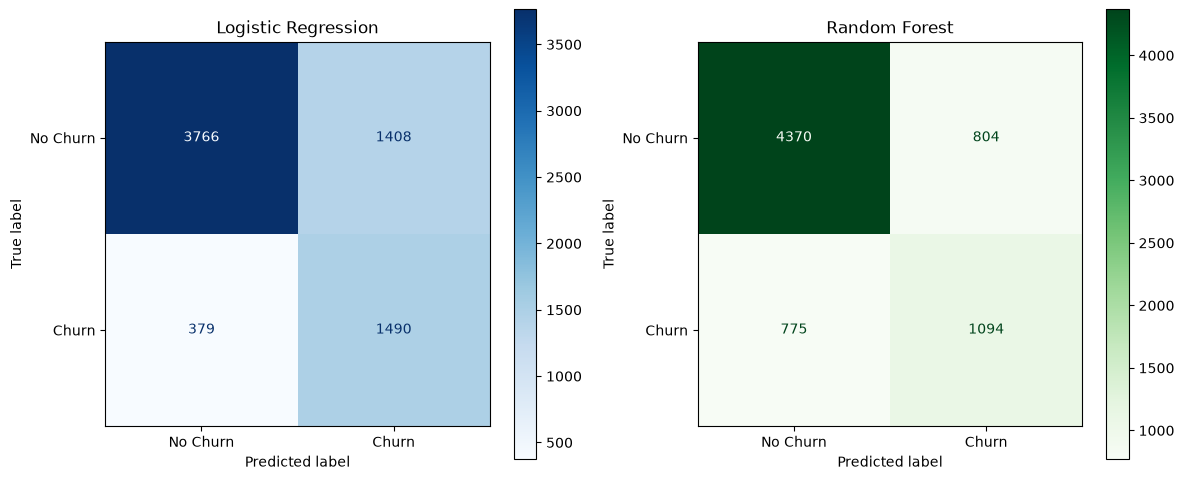

In [30]:
oof_lr = cross_val_predict(lr_pipe, X, y, cv=cv, n_jobs=-1)
oof_rf = cross_val_predict(rf_pipe, X, y, cv=cv, n_jobs=-1)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y, oof_lr, display_labels=['No Churn', 'Churn'], ax=axes[0], cmap='Blues')
axes[0].set_title('Logistic Regression')
ConfusionMatrixDisplay.from_predictions(y, oof_rf, display_labels=['No Churn', 'Churn'], ax=axes[1], cmap='Greens')
axes[1].set_title('Random Forest')
plt.tight_layout()
plt.show()

In [31]:
for name, preds in [('Logistic Regression', oof_lr), ('Random Forest', oof_rf)]:
    cm = confusion_matrix(y, preds, normalize='true') * 100
    print(name)
    print(f'  Non-churners correctly identified (TN rate): {cm[0, 0]:.2f}%')
    print(f'  Churners correctly identified (TP rate / recall): {cm[1, 1]:.2f}%')
    print()

Logistic Regression
  Non-churners correctly identified (TN rate): 72.79%
  Churners correctly identified (TP rate / recall): 79.72%

Random Forest
  Non-churners correctly identified (TN rate): 84.46%
  Churners correctly identified (TP rate / recall): 58.53%



### Interpretation

All numbers are means over the same five stratified validation folds (standard deviations are in the second table above).

**1. Which model performed best on the primary metrics?** Logistic Regression. It has the highest ROC-AUC (0.844 vs 0.824 for Random Forest) and by far the highest churn recall (0.797 vs 0.582). It also wins on both of these metrics in every one of the five folds, so the difference is not a one-fold accident.

**2. Did the machine-learning models beat the baseline?** Yes on the metrics that matter. The baseline predicts "No churn" for everyone, so it gets ROC-AUC 0.50 and recall 0.00, while both models reach ROC-AUC above 0.82 and find most of the churners (precision of the baseline is also 0 because it never predicts churn). Accuracy is where the baseline looks deceptively good: 0.735 versus 0.746 for Logistic Regression, a gain of barely one point. This is exactly why accuracy alone is not enough for this problem. Random Forest has the best accuracy (0.778), but that comes from being more cautious about flagging customers, not from being the better churn detector.

**3. Precision and recall trade-off.** The two models sit at different points on this trade-off. Logistic Regression catches about 80% of churners but only about 51% of the customers it flags actually churn (precision 0.514). Random Forest catches about 58% of churners with a precision of 0.581. In the out-of-fold confusion matrices this shows up as Logistic Regression correctly clearing 72.8% of loyal customers and Random Forest clearing 84.9%. As a rough illustration, among 1,000 customers (about 265 churners), Logistic Regression would find around 211 of them and Random Forest around 154, but Logistic Regression also sends more retention offers to customers who would have stayed.

**4. Which model to investigate further?** Logistic Regression. It is best on ROC-AUC and recall, which I chose as the primary metrics because missing a churner is the costlier mistake, and it is also the easier model to interpret and explain to a retention team. Random Forest should not be dropped: it is close on ROC-AUC and has better precision, so it could become the better choice if retention offers turn out to be expensive. Both models are untuned, so this is a recommendation for the next round of work, not a final decision.

## 12. Conclusions and Limitations

**Conclusions.**
- The cleaning work was small but important: `TotalCharges` had to be converted from text, its 11 blanks turned out to be customers with zero tenure (so 0 was the correct value, not the mean), and redundant "No phone service" / "No internet service" labels and the odd `SeniorCitizen` coding were standardised.
- With preprocessing and oversampling kept inside a pipeline, and all models scored on the same five stratified folds, Logistic Regression is the stronger candidate for finding churners (ROC-AUC 0.844, recall 0.797). Random Forest trades recall for precision and accuracy.
- Both models clearly beat the baseline on ROC-AUC and recall, but the accuracy gain over the baseline is small, so accuracy should not be used to judge them.

**5. Limitations that remain before real-world use.**
- **No tuning.** Both models run on default hyperparameters, and the decision threshold is fixed at 0.5. Tuning the model and especially the threshold could move recall and precision a lot.
- **Costs are assumed.** I argued that false negatives cost more than false positives, but the dataset has no real figures for customer value or offer cost. The best threshold depends on those numbers.
- **SMOTE with one-hot columns.** SMOTE interpolates between neighbours, which creates fractional values in 0/1 dummy columns. A method designed for mixed data (such as SMOTENC) or class weights should be compared.
- **Precision is modest.** Roughly half of the flagged customers would not have left, so a large part of the retention budget would go to the wrong people.
- **Snapshot data.** `tenure` and `TotalCharges` are measured differently for churned and current customers, and the data covers one point in time. The model has not been tested on data from a later period, so its performance on future customers is unknown.
- **No calibration, fairness or external validation.** The predicted probabilities have not been checked for calibration, features such as `gender` and `SeniorCitizen` have not been reviewed for fairness concerns, and there is no separate dataset to confirm the results.
- **One cross-validation run.** The gaps between models are consistent across folds, but they come from a single fixed split of the data (seed 42).

For these reasons, I do not consider either model production-ready. The results show a sound, reproducible workflow and a promising starting point, not a finished system.

## AI assistant used: Claude (Anthropic), through the Claude chat app.

How I use AI in general. In my earlier projects I used an AI assistant to guide me while writing code, to explain machine-learning concepts, the project, the data and the decisions behind it, and to help me understand code or steps I could not follow. In this assignment I did something different. I asked the assistant to review my notebook against the assignment PDF and then to make the edits, so most of the new code and text in this notebook was written by the AI assistant. The original notebook cells (the first version with the data loading, encoding, SMOTE, Logistic Regression and Random Forest) were my own draft. I am responsible for understanding and being able to explain everything in this notebook.